In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score
from matplotlib.patches import Ellipse

### 1. Read the data + Check the input

In [2]:
df = pd.read_csv("data/processed/clustering_features_standardized.csv")

print(df.shape)

df.head()

(1979, 22)


,PLAYER_ID,PLAYER_NAME,SEASON,TEAM_ID,TEAM_ABBREVIATION,PLAYER_POSITION_defend_rim,GP_player_totals,MIN_player_totals,USG_PCT_player_advanced,AST_PCT_player_advanced,...,PCT_PTS_FT_player_scoring,PCT_PTS_FB_player_scoring,SHOT_SHARE_PAINT_NON_RA,SHOT_SHARE_MID_RANGE,SHOT_SHARE_CORNER_3,SHOT_SHARE_ABOVE_BREAK_3,PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,PCT_BOX_OUTS_DEF_hustle,FREQ_defend_rim,SCREEN_ASSISTS_PER36
0,2544,LeBron James,2021-22,1610612747,LAL,F,56,2084.335000,2.436660,1.772005,...,0.129093,0.561810,-1.111832,0.788489,-1.026086,0.323003,0.706144,-0.369247,0.213456,-0.207812
1,2544,LeBron James,2022-23,1610612747,LAL,F,55,1953.940000,2.528841,1.903393,...,0.271727,1.590602,-0.492258,1.072250,-1.062786,-0.029718,0.618643,-0.576259,0.456607,-0.373665
2,2544,LeBron James,2023-24,1610612747,LAL,F,71,2503.683333,1.846697,2.500612,...,0.432191,1.289059,-0.375199,0.507270,-0.966873,-0.230315,-0.089318,-0.203637,-0.196862,-0.447988
3,2544,LeBron James,2024-25,1610612747,LAL,F,70,2444.446667,1.957315,2.942554,...,0.164752,1.147157,0.308845,1.078706,-1.029540,-0.033887,-0.407502,-0.272641,-0.713558,-0.300189
4,2544,LeBron James,2025-26,1610612747,LAL,F,60,1989.055000,1.422662,2.261724,...,0.753117,2.601655,0.089208,1.078730,-0.755521,-0.483789,0.014092,0.189686,-0.576785,-0.415770


In [3]:
feature_cols = [
    "USG_PCT_player_advanced",
    "AST_PCT_player_advanced",
    "OREB_PCT_player_advanced",
    "DREB_PCT_player_advanced",
    "PCT_PTS_FT_player_scoring",
    "PCT_PTS_FB_player_scoring",
    "SHOT_SHARE_PAINT_NON_RA",
    "SHOT_SHARE_MID_RANGE",
    "SHOT_SHARE_CORNER_3",
    "SHOT_SHARE_ABOVE_BREAK_3",
    "PCT_LOOSE_BALLS_RECOVERED_DEF_hustle",
    "PCT_BOX_OUTS_DEF_hustle",
    "FREQ_defend_rim",
    "SCREEN_ASSISTS_PER36",
]

X = df[feature_cols].copy()

print(X.shape)
X.head()

(1979, 14)


,USG_PCT_player_advanced,AST_PCT_player_advanced,OREB_PCT_player_advanced,DREB_PCT_player_advanced,PCT_PTS_FT_player_scoring,PCT_PTS_FB_player_scoring,SHOT_SHARE_PAINT_NON_RA,SHOT_SHARE_MID_RANGE,SHOT_SHARE_CORNER_3,SHOT_SHARE_ABOVE_BREAK_3,PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,PCT_BOX_OUTS_DEF_hustle,FREQ_defend_rim,SCREEN_ASSISTS_PER36
0,2.436660,1.772005,-0.435866,1.018149,0.129093,0.561810,-1.111832,0.788489,-1.026086,0.323003,0.706144,-0.369247,0.213456,-0.207812
1,2.528841,1.903393,-0.375396,1.135381,0.271727,1.590602,-0.492258,1.072250,-1.062786,-0.029718,0.618643,-0.576259,0.456607,-0.373665
2,1.846697,2.500612,-0.587042,0.764145,0.432191,1.289059,-0.375199,0.507270,-0.966873,-0.230315,-0.089318,-0.203637,-0.196862,-0.447988
3,1.957315,2.942554,-0.435866,1.057226,0.164752,1.147157,0.308845,1.078706,-1.029540,-0.033887,-0.407502,-0.272641,-0.713558,-0.300189
4,1.422662,2.261724,-0.677748,0.529679,0.753117,2.601655,0.089208,1.078730,-0.755521,-0.483789,0.014092,0.189686,-0.576785,-0.415770


In [4]:
all_finite = np.isfinite(X.to_numpy()).all()
print("All metrics are finite values:", all_finite)

max_abs_z = X.abs().max().sort_values(ascending=False)
max_abs_z.head()

All metrics are finite values: True


SHOT_SHARE_CORNER_3         6.585413
PCT_BOX_OUTS_DEF_hustle     5.917173
SHOT_SHARE_MID_RANGE        5.763447
SHOT_SHARE_PAINT_NON_RA     5.736641
OREB_PCT_player_advanced    4.704116
dtype: float64

All 14 clustering features contain only finite values. The corner three-point attempt share has the largest absolute z-score (6.59), and we retain all observations for the initial K-means analysis.

### 2. K-means Clustering Across Different Values of K

#### 2.1 Clustering All Players Together

In [5]:
# K = 2

kmeans = KMeans(n_clusters=2, n_init=30, random_state=7)
labels = kmeans.fit_predict(X)

print("Groups of the top 10 records：", labels[:10])
pd.Series(labels).value_counts().sort_index()

Groups of the top 10 records： [0 0 0 0 0 0 1 0 0 0]


0    1526
1     453
Name: count, dtype: int64

In [6]:
score_k2 = silhouette_score(X, labels) # Assessing the degree of separation between groups
print(f"Silhouette score: {score_k2:.4f}")
print(f"Inertia: {kmeans.inertia_:.2f}") # The sum of the squared distances from each record to its group centre

Silhouette score: 0.2917
Inertia: 20648.18


In [7]:
# K = 2 ~ K = 12
results = []

for k in range(2, 13):
    model = KMeans(n_clusters=k, n_init=30, random_state=7)
    group_labels = model.fit_predict(X)
    group_counts = pd.Series(group_labels).value_counts()

    results.append({
        "K": k,
        "Silhouette": silhouette_score(X, group_labels),
        "Inertia": model.inertia_,
        "Smallest cluster": group_counts.min(),
    })

k_results = pd.DataFrame(results)
k_results.round(4)

,K,Silhouette,Inertia,Smallest cluster
0,2,0.2917,20648.1775,453
1,3,0.2071,17137.4927,420
2,4,0.1582,15988.1561,372
3,5,0.1312,15174.8403,297
4,6,0.1254,14505.7899,220
5,7,0.1205,14011.3783,216
6,8,0.1217,13495.2163,117
7,9,0.1126,13130.1712,129
8,10,0.1142,12807.9290,94
9,11,0.1127,12505.7222,94


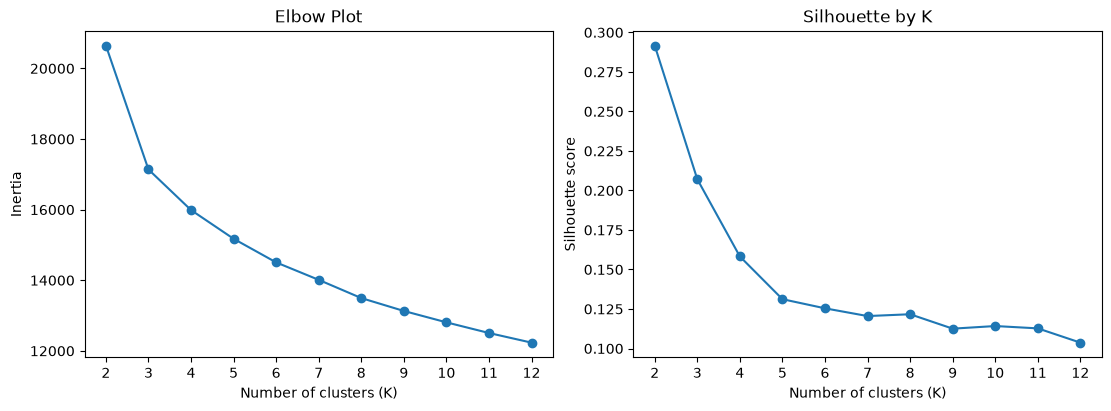

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

axes[0].plot(k_results["K"], k_results["Inertia"], marker="o")
axes[0].set(title="Elbow Plot", xlabel="Number of clusters (K)", ylabel="Inertia")

axes[1].plot(k_results["K"], k_results["Silhouette"], marker="o")
axes[1].set(title="Silhouette by K", xlabel="Number of clusters (K)", ylabel="Silhouette score")

for ax in axes:
    ax.set_xticks(k_results["K"])

plt.show()

In [9]:
# Stability check: bootstrap ARI for K=2..8
from sklearn.metrics import adjusted_rand_score

X_arr = X.to_numpy()
rng = np.random.default_rng(0)
rows = []

for k in range(2, 9):
    base = KMeans(n_clusters=k, n_init=30, random_state=7).fit(X_arr)
    aris = []
    for b in range(20):
        idx = rng.choice(len(X_arr), size=len(X_arr), replace=True)   # resample rows
        boot = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X_arr[idx])
        aris.append(adjusted_rand_score(base.labels_, boot.predict(X_arr)))
    rows.append({"K": k,
                 "Stab_mean": round(np.mean(aris), 2),
                 "Stab_min": round(np.min(aris), 2)})

stab = pd.DataFrame(rows).set_index("K")
display(stab)

,Stab_mean,Stab_min
K,,
2,0.98,0.97
3,0.94,0.87
4,0.83,0.63
5,0.70,0.40
6,0.69,0.49
7,0.58,0.44
8,0.71,0.44


K=3 is highly stable (bootstrap ARI ≈ 0.94), and stability drops from K=4 onward (≤ 0.83). Together with the elbow at K=3, this supports K=3 as the main solution.

In [35]:
# check K = 2
profile_k2 = X.copy()
profile_k2["Cluster"] = labels

means_k2 = profile_k2.groupby("Cluster")[feature_cols].mean().T
means_k2["Diff(1 - 0)"] = means_k2[1] - means_k2[0]


difference = means_k2["Diff(1 - 0)"]
means_k2["Higher cluster"] = np.select(
    [difference > 0, difference < 0],
    ["1", "0"],
    default="Tie",
)


# Basketball interpretation
basketball_notes = {
    "SCREEN_ASSISTS_PER36": "More screen assists",
    "OREB_PCT_player_advanced": "Higher offensive rebound rate",
    "DREB_PCT_player_advanced": "Higher defensive rebound rate",
    "PCT_BOX_OUTS_DEF_hustle": "Higher defensive box-out share",
    "SHOT_SHARE_ABOVE_BREAK_3": "More non-corner threes",
    "FREQ_defend_rim": "Higher rim-defense share",
    "PCT_PTS_FB_player_scoring": "Higher fast-break scoring share",
    "SHOT_SHARE_CORNER_3": "More corner threes",
    "PCT_LOOSE_BALLS_RECOVERED_DEF_hustle": "Higher defensive recovery share",
    "SHOT_SHARE_PAINT_NON_RA": "More non-restricted paint shots",
    "PCT_PTS_FT_player_scoring": "Higher free-throw scoring share",
    "SHOT_SHARE_MID_RANGE": "More mid-range shots",
    "AST_PCT_player_advanced": "Higher assist rate",
    "USG_PCT_player_advanced": "Similar usage rates",
}

means_k2["Basketball interpretation"] = means_k2.index.map(basketball_notes)

means_k2.sort_values("Diff(1 - 0)", key=abs, ascending=False).round(2)

Cluster,0,1,Diff(1 - 0),Higher cluster,Basketball interpretation
SCREEN_ASSISTS_PER36,-0.47,1.57,2.04,1,More screen assists
OREB_PCT_player_advanced,-0.44,1.47,1.91,1,Higher offensive rebound rate
DREB_PCT_player_advanced,-0.37,1.26,1.63,1,Higher defensive rebound rate
PCT_BOX_OUTS_DEF_hustle,0.33,-1.11,-1.44,0,Higher defensive box-out share
SHOT_SHARE_ABOVE_BREAK_3,0.31,-1.05,-1.36,0,More non-corner threes
FREQ_defend_rim,-0.26,0.89,1.15,1,Higher rim-defense share
PCT_PTS_FB_player_scoring,0.26,-0.88,-1.14,0,Higher fast-break scoring share
SHOT_SHARE_CORNER_3,0.25,-0.84,-1.09,0,More corner threes
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,0.19,-0.63,-0.82,0,Higher defensive recovery share
SHOT_SHARE_PAINT_NON_RA,-0.15,0.51,0.66,1,More non-restricted paint shots


Cluster 0 (1,526 player-seasons) showed a **perimeter and transition style**, with higher shares of both corner and above-the-break three-point attempts and a larger share of points from fast breaks. Cluster 1 (453 player-seasons) showed an **interior style**, with more screen assists per 36 minutes, higher offensive and defensive rebound rates, and more frequent defense near the rim. Across all 1,979 player-seasons, the two groups had similar average usage rates, while screening and rebounding showed the largest differences.

In [11]:
# check K = 3
kmeans_k3 = KMeans(n_clusters=3, n_init=30, random_state=7)
labels_k3 = kmeans_k3.fit_predict(X)

profile_k3 = X.copy()
profile_k3["Cluster"] = labels_k3

means_k3 = profile_k3.groupby("Cluster")[feature_cols].mean().T
means_k3["Highest cluster"] = means_k3[[0, 1, 2]].idxmax(axis=1)
means_k3["Spread"] = means_k3[[0, 1, 2]].max(axis=1) - means_k3[[0, 1, 2]].min(axis=1)

means_k3.sort_values("Spread", ascending=False).round(2)

Cluster,0,1,2,Highest cluster,Spread
SCREEN_ASSISTS_PER36,-0.39,1.67,-0.53,1,2.20
OREB_PCT_player_advanced,-0.32,1.55,-0.55,1,2.09
SHOT_SHARE_CORNER_3,0.82,-0.85,-0.54,0,1.66
DREB_PCT_player_advanced,-0.39,1.27,-0.28,1,1.66
PCT_BOX_OUTS_DEF_hustle,0.21,-1.15,0.44,2,1.59
SHOT_SHARE_ABOVE_BREAK_3,0.44,-1.09,0.11,0,1.53
USG_PCT_player_advanced,-0.54,-0.26,0.87,2,1.42
AST_PCT_player_advanced,-0.49,-0.45,0.92,2,1.41
PCT_PTS_FB_player_scoring,0.40,-0.92,0.05,0,1.32
FREQ_defend_rim,-0.20,0.94,-0.33,1,1.27


In [12]:
# check K = 2 in K = 3
comparison = pd.crosstab(
    pd.Series(labels, name="K=2 cluster"),
    pd.Series(labels_k3, name="K=3 cluster"),
    normalize="index",
)

(comparison * 100).round(1)

K=3 cluster,0,1,2
K=2 cluster,,,
0,57.4,0.1,42.5
1,1.5,92.5,6.0


With \(K=3\), we can tentatively describe the three clusters as follows:
- Cluster 0 — Perimeter Shooters and Transition Scorers. These players move into open space to catch and shoot, and they score on fast breaks.
- Cluster 1 — Interior Screeners and Rebounders. These players set screens to create space for teammates and compete for rebounds.
- Cluster 2 — On-Ball Playmakers and Scorers. These players direct the offense with the ball in their hands, deciding when to shoot and when to create a shot for a teammate.

In [13]:
# Representative players for K=3 (closest to centroid)
role_names = {
    0: "Perimeter shooting & transition",
    1: "Interior screening & rebounding",
    2: "On-ball playmaking & scoring",
}

dist = np.linalg.norm(X.to_numpy() - kmeans_k3.cluster_centers_[labels_k3], axis=1)

players_k3 = df[["PLAYER_ID", "PLAYER_NAME", "SEASON", "PLAYER_POSITION_defend_rim", "MIN_player_totals"]].assign(
    Cluster=labels_k3,
    Role=pd.Series(labels_k3).map(role_names).to_numpy(),
    Dist=dist,
)

# closest to centre, one season per player, at least 1,000 minutes
reps_k3 = (
    players_k3[players_k3["MIN_player_totals"] >= 1000]
    .sort_values("Dist")
    .drop_duplicates(["Cluster", "PLAYER_ID"])
    .groupby("Cluster")
    .head(6)
    .sort_values(["Cluster", "Dist"])
)

display(reps_k3[["Cluster", "Role", "PLAYER_NAME", "SEASON", "PLAYER_POSITION_defend_rim", "Dist"]].round(2))
display(players_k3.groupby("Role").agg(Records=("PLAYER_ID", "size"), Players=("PLAYER_ID", "nunique")))

,Cluster,Role,PLAYER_NAME,SEASON,PLAYER_POSITION_defend_rim,Dist
1115,0,Perimeter shooting & transition,Cameron Johnson,2021-22,F,0.97
1398,0,Perimeter shooting & transition,Herbert Jones,2025-26,F,0.98
632,0,Perimeter shooting & transition,Alex Caruso,2023-24,G,1.12
1234,0,Perimeter shooting & transition,Aaron Nesmith,2023-24,G-F,1.28
1886,0,Perimeter shooting & transition,Ja'Kobe Walter,2024-25,G,1.28
956,0,Perimeter shooting & transition,Rui Hachimura,2024-25,F,1.29
695,1,Interior screening & rebounding,Jarrett Allen,2022-23,C,1.31
774,1,Interior screening & rebounding,Marvin Bagley III,2025-26,F,1.57
1206,1,Interior screening & rebounding,Onyeka Okongwu,2024-25,F-C,1.59
1274,1,Interior screening & rebounding,Isaiah Stewart,2024-25,F-C,1.61


,Records,Players
Role,,
Interior screening & rebounding,420,162
On-ball playmaking & scoring,676,270
Perimeter shooting & transition,883,391


Representative players support the role labels: 3&D wings (C. Johnson, H. Jones, Caruso), rim-running bigs (J. Allen, Okongwu, Claxton), and secondary ball handlers (Reaves, Brogdon, Rozier). Each role mixes listed positions (e.g., F and G in the perimeter role), supporting position-less play. Stars sit far from centroids because of their extreme profiles, so centroids describe common rather than star roles. The interior role is the most heterogeneous (largest distances). Each role includes 160+ unique players, so no role is driven by a few repeated players.

In [14]:
# Sensitivity analysis for K=3 (ARI vs. main solution)
from sklearn.metrics import adjusted_rand_score

X_arr = X.to_numpy()

def refit(Xs):
    return KMeans(n_clusters=3, n_init=30, random_state=7).fit_predict(Xs)

def drop(cols):
    return X.drop(columns=cols).to_numpy()

rows = []
# 1) feature choices
checks = {
    "PCA, 4 PCs":          PCA(n_components=4).fit_transform(X_arr),
    "Drop ScrAst":         drop(["SCREEN_ASSISTS_PER36"]),
    "Drop defense/hustle": drop(["PCT_LOOSE_BALLS_RECOVERED_DEF_hustle",
                                 "PCT_BOX_OUTS_DEF_hustle", "FREQ_defend_rim"]),
}
for name, Xs in checks.items():
    rows.append({"Check": name, "n": len(Xs),
                 "ARI": adjusted_rand_score(labels_k3, refit(Xs))})

# 2) stricter minutes threshold (compare on the same rows)
for t in [800, 1200]:
    m = (df["MIN_player_totals"] >= t).to_numpy()
    rows.append({"Check": f"MIN >= {t}", "n": m.sum(),
                 "ARI": adjusted_rand_score(labels_k3[m], refit(X_arr[m]))})

# 3) each season on its own
for s in sorted(df["SEASON"].unique()):
    m = (df["SEASON"] == s).to_numpy()
    rows.append({"Check": f"Season {s}", "n": m.sum(),
                 "ARI": adjusted_rand_score(labels_k3[m], refit(X_arr[m]))})

# 4) resample players (not rows): keeps all seasons of a player together
rng = np.random.default_rng(0)
pids = df["PLAYER_ID"].to_numpy()
unique_pids = np.unique(pids)
boot_ari = []
for b in range(20):
    pick = rng.choice(unique_pids, size=len(unique_pids), replace=True)
    idx = np.concatenate([np.flatnonzero(pids == p) for p in pick])
    km = KMeans(n_clusters=3, n_init=10, random_state=b).fit(X_arr[idx])
    boot_ari.append(adjusted_rand_score(labels_k3, km.predict(X_arr)))
rows.append({"Check": "Player bootstrap (mean)", "n": len(X_arr), "ARI": np.mean(boot_ari)})

sens = pd.DataFrame(rows).set_index("Check").round(3)
display(sens)

,n,ARI
Check,,
"PCA, 4 PCs",1979,0.969
Drop ScrAst,1979,0.917
Drop defense/hustle,1979,0.890
MIN >= 800,1562,0.969
MIN >= 1200,1156,0.780
Season 2021-22,396,0.937
Season 2022-23,388,0.889
Season 2023-24,385,0.906
Season 2024-25,401,0.976


#### Conclusion

Across all players, K = 2 had the highest average silhouette score (0.292) and separated players into two broad groups: perimeter players and interior players. At K = 3, the score decreased to 0.207, but the interior group remained largely intact, while the perimeter group split into two distinct styles: perimeter shooting and transition scoring, and on-ball playmaking and scoring. We therefore use K = 3 to describe player roles and retain K = 2 as a baseline.

### 2.2 Cluster Distribution by Player Position

In [15]:
position = df["PLAYER_POSITION_defend_rim"]

position_pct = pd.crosstab(
    position,
    labels_k3,
    rownames=["Listed position"],
    colnames=["K=3 cluster"],
    normalize="index",
)

position_order = ["G", "G-F", "F-G", "F", "F-C", "C-F", "C"]
position_pct = position_pct.reindex(position_order)

position_table = (position_pct * 100).round(1)
position_table.insert(0, "Records", position.value_counts())
position_table

K=3 cluster,Records,0,1,2
Listed position,,,,
G,780,45.4,0.0,54.6
G-F,167,65.3,1.8,32.9
F-G,73,53.4,2.7,43.8
F,562,58.5,17.1,24.4
F-C,141,20.6,66.7,12.8
C-F,85,15.3,75.3,9.4
C,171,5.8,94.2,0.0


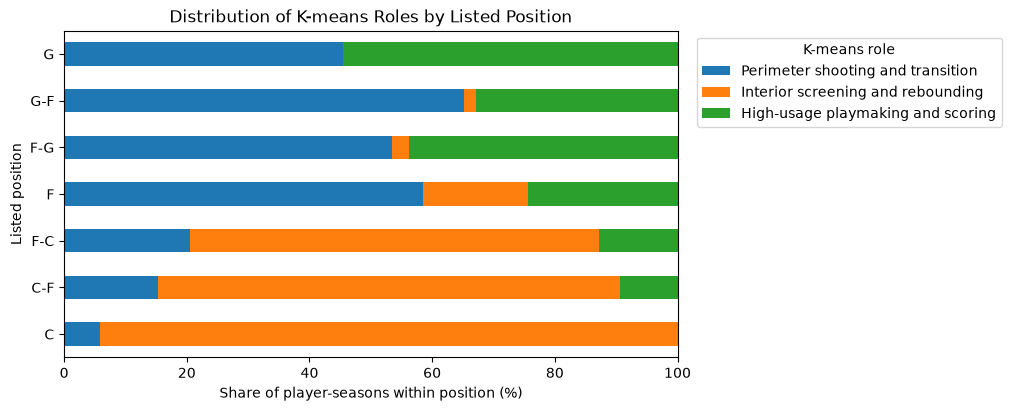

In [16]:
position_plot = (position_pct * 100).rename(columns={
    0: "Perimeter shooting and transition",
    1: "Interior screening and rebounding",
    2: "High-usage playmaking and scoring",
})

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")

position_plot.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()

ax.set(
    title="Distribution of K-means Roles by Listed Position",
    xlabel="Share of player-seasons within position (%)",
    ylabel="Listed position",
    xlim=(0, 100),
)
ax.legend(title="K-means role", loc="upper left", bbox_to_anchor=(1.02, 1))

plt.show()

**Centers showed the clearest link between position and role.** Among player-seasons listed as C, 94.2% fell into the interior screening and rebounding role. The same role was also the most common among C-F (75.3%) and F-C (66.7%) records, although both hybrid groups included a larger share of perimeter players.

**Guards were divided between two styles.** Among records listed as G, 54.6% fell into on-ball playmaking and scoring, while 45.4% fell into perimeter shooting and transition. The hybrid labels showed a similar two-role pattern, but with different proportions. Perimeter shooting and transition accounted for 65.3% of G-F records and 53.4% of F-G records.

**Forwards showed the widest mix of roles.** Among records listed as F, perimeter shooting and transition was the most common role (58.5%), followed by on-ball playmaking and scoring (24.4%) and interior screening and rebounding (17.1%). All three styles were represented even among players with the same F label.

Listed position was most informative for centers, who generally played an interior role. For guards, clustering revealed a distinction between perimeter shooting and on-ball creation. For forwards, it showed that a single position label covered all three styles. These differences motivate the next question: what additional playing styles emerge when we cluster players within each position?

### 2.3 K-means Clustering Within Each Position

#### 2.3.1 Center

In [17]:

X_c = X.loc[position.eq("C")]
print("Center data shape:", X_c.shape)

kmeans_c = KMeans(n_clusters=2, n_init=30, random_state=7)
labels_c = kmeans_c.fit_predict(X_c)
print(pd.Series(labels_c).value_counts().sort_index())

profile_c = X_c.assign(Cluster=labels_c)
means_c = profile_c.groupby("Cluster")[feature_cols].mean().T
means_c["Difference (1 - 0)"] = means_c[1] - means_c[0]

means_c.sort_values("Difference (1 - 0)", key=abs, ascending=False).round(2)

Center data shape: (171, 14)
0     50
1    121
Name: count, dtype: int64


Cluster,0,1,Difference (1 - 0)
SHOT_SHARE_ABOVE_BREAK_3,-0.09,-1.60,-1.51
OREB_PCT_player_advanced,0.85,2.16,1.32
SCREEN_ASSISTS_PER36,1.26,2.18,0.92
PCT_BOX_OUTS_DEF_hustle,-0.55,-1.46,-0.91
USG_PCT_player_advanced,0.33,-0.47,-0.80
SHOT_SHARE_CORNER_3,-0.48,-1.22,-0.74
AST_PCT_player_advanced,0.03,-0.65,-0.69
SHOT_SHARE_PAINT_NON_RA,0.38,0.90,0.52
PCT_PTS_FT_player_scoring,-0.10,0.34,0.45
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,-0.44,-0.87,-0.43


In [18]:
kmeans_c3 = KMeans(n_clusters=3, n_init=30, random_state=7)
labels_c3 = kmeans_c3.fit_predict(X_c)

center_results = []

for k, model, group_labels in [
    (2, kmeans_c, labels_c),
    (3, kmeans_c3, labels_c3),
]:
    counts = pd.Series(group_labels).value_counts().sort_index()
    center_results.append({
        "K": k,
        "Silhouette": silhouette_score(X_c, group_labels),
        "Inertia": model.inertia_,
        "Records per cluster": counts.tolist(),
    })

pd.DataFrame(center_results).round(4)

,K,Silhouette,Inertia,Records per cluster
0,2,0.1864,1463.1373,"[50, 121]"
1,3,0.1737,1225.4797,"[65, 81, 25]"


In [19]:
profile_c3 = X_c.assign(Cluster=labels_c3)

means_c3 = profile_c3.groupby("Cluster")[feature_cols].mean().T
means_c3["Spread"] = means_c3.max(axis=1) - means_c3.min(axis=1)

means_c3.sort_values("Spread", ascending=False).round(2)

Cluster,0,1,2,Spread
SHOT_SHARE_PAINT_NON_RA,1.81,0.28,-0.46,2.27
SHOT_SHARE_ABOVE_BREAK_3,-1.19,-1.62,0.41,2.03
OREB_PCT_player_advanced,1.41,2.40,0.71,1.69
SHOT_SHARE_CORNER_3,-1.16,-1.21,0.06,1.26
PCT_BOX_OUTS_DEF_hustle,-0.89,-1.67,-0.45,1.22
DREB_PCT_player_advanced,1.85,1.57,0.64,1.20
SCREEN_ASSISTS_PER36,1.88,2.21,1.03,1.18
USG_PCT_player_advanced,0.39,-0.73,-0.29,1.11
PCT_PTS_FT_player_scoring,0.17,0.48,-0.56,1.04
AST_PCT_player_advanced,0.10,-0.81,-0.73,0.91


##### Comparing Two- and Three-Cluster Solutions

In [20]:
pd.crosstab(
    labels_c,
    labels_c3,
    rownames=["K=2 cluster"],
    colnames=["K=3 cluster"],
)

K=3 cluster,0,1,2
K=2 cluster,,,
0,25,0,25
1,40,81,0


We kept K = 2 as our main solution for centers. It had a slightly higher silhouette score than K = 3 (0.1864 vs. 0.1737) and captured two clear tendencies: more perimeter shooting and higher usage, or more screening and offensive rebounding. The three-cluster solution also identified a subgroup of 25 player-seasons with higher three-point attempt shares and lower assist rates than the rest of their original group.

#### 2.3.2 Guards

In [21]:
X_g = X.loc[position.eq("G")]
print("Guard data shape:", X_g.shape)

guard_results = []
guard_labels = {}

for k in [2, 3]:
    model_g = KMeans(n_clusters=k, n_init=30, random_state=7)
    labels_g = model_g.fit_predict(X_g)
    guard_labels[k] = labels_g

    counts_g = pd.Series(labels_g).value_counts().sort_index()
    guard_results.append({
        "K": k,
        "Silhouette": silhouette_score(X_g, labels_g),
        "Inertia": model_g.inertia_,
        "Records per cluster": counts_g.tolist(),
    })

pd.DataFrame(guard_results).round(4)

Guard data shape: (780, 14)


,K,Silhouette,Inertia,Records per cluster
0,2,0.1939,5949.9972,"[413, 367]"
1,3,0.1623,5481.9703,"[160, 351, 269]"


In [22]:
profile_g2 = X_g.assign(Cluster=guard_labels[2])

means_g2 = profile_g2.groupby("Cluster")[feature_cols].mean().T
means_g2["Difference (1 - 0)"] = means_g2[1] - means_g2[0]

means_g2.sort_values("Difference (1 - 0)", key=abs, ascending=False).round(2)

Cluster,0,1,Difference (1 - 0)
AST_PCT_player_advanced,1.23,-0.25,-1.48
USG_PCT_player_advanced,0.79,-0.54,-1.32
SHOT_SHARE_CORNER_3,-0.56,0.73,1.28
SHOT_SHARE_PAINT_NON_RA,0.48,-0.65,-1.13
PCT_PTS_FT_player_scoring,0.31,-0.60,-0.91
SHOT_SHARE_MID_RANGE,0.57,-0.17,-0.74
PCT_PTS_FB_player_scoring,0.05,0.48,0.42
SHOT_SHARE_ABOVE_BREAK_3,0.26,0.66,0.39
PCT_BOX_OUTS_DEF_hustle,0.61,0.37,-0.24
PCT_LOOSE_BALLS_RECOVERED_DEF_hustle,0.20,0.40,0.20


In [23]:
profile_g3 = X_g.assign(Cluster=guard_labels[3])

means_g3 = profile_g3.groupby("Cluster")[feature_cols].mean().T
means_g3["Spread"] = means_g3.max(axis=1) - means_g3.min(axis=1)

means_g3.sort_values("Spread", ascending=False).round(2)

Cluster,0,1,2,Spread
AST_PCT_player_advanced,-0.05,1.35,-0.18,1.53
USG_PCT_player_advanced,-0.49,0.94,-0.46,1.43
SHOT_SHARE_CORNER_3,0.36,-0.61,0.71,1.32
SHOT_SHARE_ABOVE_BREAK_3,-0.23,0.32,1.02,1.25
SHOT_SHARE_PAINT_NON_RA,0.01,0.46,-0.77,1.23
PCT_PTS_FT_player_scoring,0.08,0.34,-0.83,1.18
PCT_PTS_FB_player_scoring,1.08,-0.05,0.15,1.13
SHOT_SHARE_MID_RANGE,-0.41,0.68,-0.01,1.09
PCT_BOX_OUTS_DEF_hustle,-0.08,0.67,0.61,0.74
OREB_PCT_player_advanced,-0.17,-0.73,-0.72,0.56


We kept K = 2 as the main solution for guards. It had a higher silhouette score than K = 3 (0.1939 vs. 0.1623) and distinguished higher-usage playmakers from lower-usage guards who took a larger share of their shots from the corners. The three-cluster solution also identified a group with a higher share of fast-break points, which we report as an exploratory finding.

#### 2.3.3 Forwards

In [24]:
X_f = X.loc[position.eq("F")]
print("Forward data shape:", X_f.shape)

forward_results = []
forward_labels = {}

for k in [2, 3]:
    model_f = KMeans(n_clusters=k, n_init=30, random_state=7)
    labels_f = model_f.fit_predict(X_f)
    forward_labels[k] = labels_f

    counts_f = pd.Series(labels_f).value_counts().sort_index()
    forward_results.append({
        "K": k,
        "Silhouette": silhouette_score(X_f, labels_f),
        "Inertia": model_f.inertia_,
        "Records per cluster": counts_f.tolist(),
    })

pd.DataFrame(forward_results).round(4)

Forward data shape: (562, 14)


,K,Silhouette,Inertia,Records per cluster
0,2,0.1866,5190.6332,"[326, 236]"
1,3,0.2011,4395.2390,"[161, 95, 306]"


In [25]:
profile_f3 = X_f.assign(Cluster=forward_labels[3])

means_f3 = profile_f3.groupby("Cluster")[feature_cols].mean().T
means_f3["Spread"] = means_f3.max(axis=1) - means_f3.min(axis=1)

means_f3.sort_values("Spread", ascending=False).round(2)

Cluster,0,1,2,Spread
OREB_PCT_player_advanced,-0.26,1.36,-0.14,1.62
SCREEN_ASSISTS_PER36,-0.35,1.24,-0.28,1.60
USG_PCT_player_advanced,0.93,-0.56,-0.55,1.49
SHOT_SHARE_ABOVE_BREAK_3,-0.23,-1.14,0.30,1.44
SHOT_SHARE_MID_RANGE,0.91,-0.42,-0.50,1.41
SHOT_SHARE_CORNER_3,-0.45,-0.46,0.89,1.35
PCT_BOX_OUTS_DEF_hustle,0.05,-1.14,0.09,1.23
PCT_PTS_FT_player_scoring,0.60,0.22,-0.51,1.11
SHOT_SHARE_PAINT_NON_RA,0.41,0.43,-0.61,1.04
AST_PCT_player_advanced,0.35,-0.60,-0.67,1.02


##### Comparing Two- and Three-Cluster Solutions

In [26]:
forward_cross = pd.crosstab(
    forward_labels[2],
    forward_labels[3],
    rownames=["K=2 cluster"],
    colnames=["K=3 cluster"],
)

forward_cross

K=3 cluster,0,1,2
K=2 cluster,,,
0,26,5,295
1,135,90,11


We kept K = 3 for players listed as forwards. It had a slightly higher silhouette score than K = 2 (0.2011 vs. 0.1866). The three-cluster solution largely preserved the perimeter shooting group and distinguished higher-usage, mid-range-oriented forwards from forwards who contributed more through screening and offensive rebounding.

#### 2.3.4 Hybrid Positions

In [27]:
hybrid_results = []

for pos in ["G-F", "F-G", "F-C", "C-F"]:
    X_pos = X.loc[position.eq(pos)]

    for k in [2, 3]:
        model = KMeans(n_clusters=k, n_init=30, random_state=7)
        labels_pos = model.fit_predict(X_pos)
        counts_pos = pd.Series(labels_pos).value_counts().sort_index()

        hybrid_results.append({
            "Position": pos,
            "Records": len(X_pos),
            "K": k,
            "Silhouette": silhouette_score(X_pos, labels_pos),
            "Records per cluster": counts_pos.tolist(),
        })

pd.DataFrame(hybrid_results).round(4)

,Position,Records,K,Silhouette,Records per cluster
0,G-F,167,2,0.1986,"[62, 105]"
1,G-F,167,3,0.1703,"[39, 69, 59]"
2,F-G,73,2,0.2486,"[48, 25]"
3,F-G,73,3,0.2459,"[23, 11, 39]"
4,F-C,141,2,0.2017,"[54, 87]"
5,F-C,141,3,0.1973,"[49, 47, 45]"
6,C-F,85,2,0.2231,"[35, 50]"
7,C-F,85,3,0.2500,"[35, 10, 40]"


Among the four hybrid positions, K = 2 had a higher silhouette score for G-F, F-G, and F-C, although the scores were nearly tied for F-G and F-C. For C-F, K = 3 scored higher (0.2500 vs. 0.2231) and identified a subgroup of 10 player-seasons with higher usage rates and a greater share of mid-range attempts. Given its small size, we treat this subgroup as an exploratory finding.

In [28]:
# Within-position K choice: silhouette + player-level bootstrap stability
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(0)
n_boot = 20
rows = []

for pos in ["C", "G", "F", "G-F", "F-G", "F-C", "C-F"]:
    mask = position.eq(pos)
    X_pos = X.loc[mask].to_numpy()
    player_ids = df.loc[mask, "PLAYER_ID"].to_numpy()
    unique_ids = np.unique(player_ids)

    # Find all records for each player at this position
    rows_by_player = {
        pid: np.flatnonzero(player_ids == pid)
        for pid in unique_ids
    }

    # Prepare the same 20 bootstrap samples for K=2 and K=3
    bootstrap_rows = []
    for b in range(n_boot):
        sampled_ids = rng.choice(unique_ids, size=len(unique_ids), replace=True)
        idx = np.concatenate([rows_by_player[pid] for pid in sampled_ids])
        bootstrap_rows.append(idx)

    for k in [2, 3]:
        base = KMeans(n_clusters=k, n_init=30, random_state=7).fit(X_pos)
        aris = []

        for b, idx in enumerate(bootstrap_rows):
            boot = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X_pos[idx])
            predicted_labels = boot.predict(X_pos)
            aris.append(adjusted_rand_score(base.labels_, predicted_labels))

        rows.append({
            "Position": pos,
            "Records": len(X_pos),
            "K": k,
            "Silhouette": round(silhouette_score(X_pos, base.labels_), 3),
            "Stability": round(np.mean(aris), 2),
        })

pos_stab = pd.DataFrame(rows).set_index(["Position", "K"])
display(pos_stab)

Records  Silhouette  Stability
Position K                                
C        2      171       0.186       0.44
         3      171       0.174       0.61
G        2      780       0.194       0.87
         3      780       0.162       0.68
F        2      562       0.187       0.78
         3      562       0.201       0.79
G-F      2      167       0.199       0.41
         3      167       0.170       0.48
F-G      2       73       0.249       0.38
         3       73       0.246       0.59
F-C      2      141       0.202       0.57
         3      141       0.197       0.73
C-F      2       85       0.223       0.72
         3       85       0.250       0.75

In [29]:
# Who is in each C-F subgroup (K=3)? Records vs. unique players
mask_cf = position.eq("C-F")
labels_cf3 = KMeans(n_clusters=3, n_init=30, random_state=7).fit_predict(X.loc[mask_cf])

cf_players = df.loc[mask_cf, ["PLAYER_ID", "PLAYER_NAME", "SEASON"]].assign(Cluster=labels_cf3)

display(cf_players.groupby("Cluster").agg(Records=("PLAYER_ID", "size"),
                                          Players=("PLAYER_ID", "nunique")))

small = cf_players["Cluster"].value_counts().idxmin()      # the smallest subgroup
display(cf_players[cf_players["Cluster"] == small]["PLAYER_NAME"].value_counts())

,Records,Players
Cluster,,
0,35,14
1,10,3
2,40,11


PLAYER_NAME
Joel Embiid          5
Bam Adebayo          4
LaMarcus Aldridge    1
Name: count, dtype: int64

#### 2.3.5 Feature Profiles of the Seven Main Subtypes

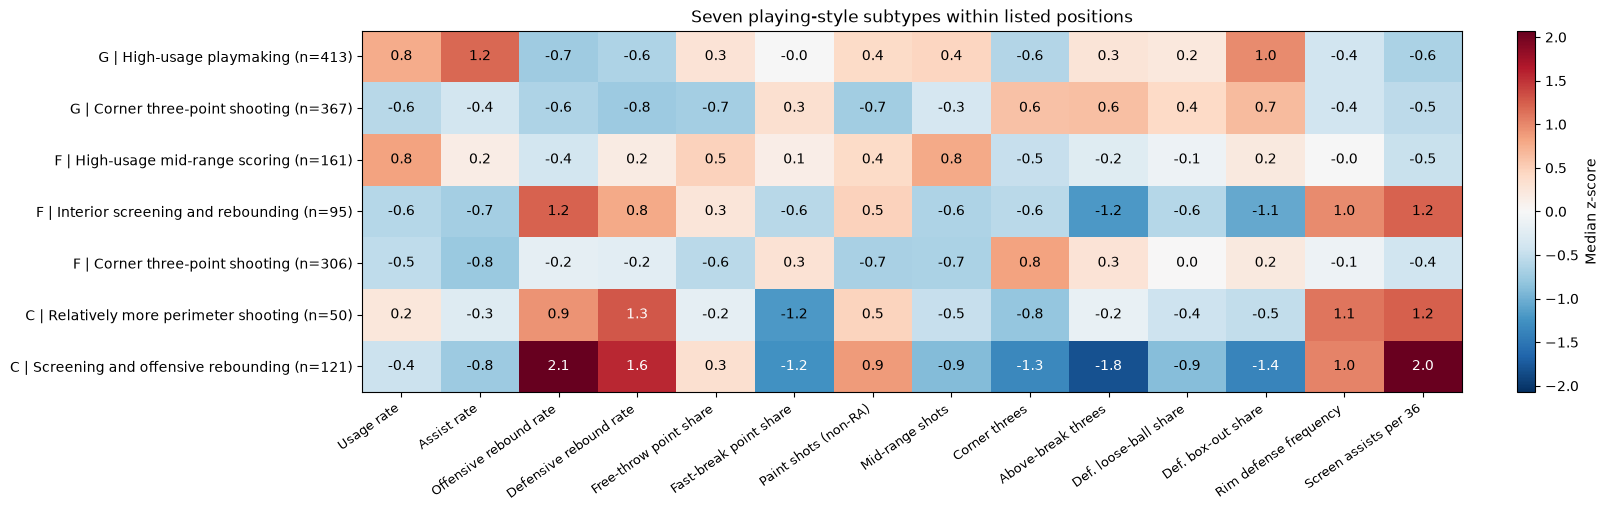

In [30]:
# Use the selected cluster labels from Section 2.3
selected_groups = [
    ("G", X_g, guard_labels[2], [
        "High-usage playmaking", "Corner three-point shooting",
    ]),
    ("F", X_f, forward_labels[3], [
        "High-usage mid-range scoring", "Interior screening and rebounding",
        "Corner three-point shooting",
    ]),
    ("C", X_c, labels_c, [
        "Relatively more perimeter shooting", "Screening and offensive rebounding",
    ]),
]

median_profiles = []

for pos, features, group_labels, role_names in selected_groups:
    grouped = features.assign(Cluster=group_labels).groupby("Cluster")
    medians = grouped[feature_cols].median()
    counts = grouped.size()

    medians.index = [
        f"{pos} | {role_names[k]} (n={counts[k]})"
        for k in medians.index
    ]
    median_profiles.append(medians)

heatmap_table = pd.concat(median_profiles)
heatmap_values = heatmap_table.to_numpy()

feature_names = {
    "USG_PCT_player_advanced": "Usage rate",
    "AST_PCT_player_advanced": "Assist rate",
    "OREB_PCT_player_advanced": "Offensive rebound rate",
    "DREB_PCT_player_advanced": "Defensive rebound rate",
    "PCT_PTS_FT_player_scoring": "Free-throw point share",
    "PCT_PTS_FB_player_scoring": "Fast-break point share",
    "SHOT_SHARE_PAINT_NON_RA": "Paint shots (non-RA)",
    "SHOT_SHARE_MID_RANGE": "Mid-range shots",
    "SHOT_SHARE_CORNER_3": "Corner threes",
    "SHOT_SHARE_ABOVE_BREAK_3": "Above-break threes",
    "PCT_LOOSE_BALLS_RECOVERED_DEF_hustle": "Def. loose-ball share",
    "PCT_BOX_OUTS_DEF_hustle": "Def. box-out share",
    "FREQ_defend_rim": "Rim defense frequency",
    "SCREEN_ASSISTS_PER36": "Screen assists per 36",
}

fig, ax = plt.subplots(figsize=(16, 5), layout="constrained")
limit = np.abs(heatmap_values).max()

image = ax.imshow(
    heatmap_values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto"
)

ax.set_xticks(
    range(len(feature_cols)),
    [feature_names[col] for col in heatmap_table.columns],
    rotation=35, ha="right", fontsize=9,
)
ax.set_yticks(range(len(heatmap_table)), heatmap_table.index)
ax.set_title("Seven playing-style subtypes within listed positions")

for i, row in enumerate(heatmap_values):
    for j, value in enumerate(row):
        color = "white" if abs(value) > 0.6 * limit else "black"
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", color=color)

fig.colorbar(image, ax=ax, label="Median z-score")
plt.show()

The heatmap summarizes each subtype using median standardized feature values. Among guards, the high-usage playmakers had higher assist and usage rates, while the shooting group took a larger share of its shots from the corners. Among forwards, the three profiles emphasized mid-range shooting and higher usage, screening and rebounding, or corner three-point shooting. Among centers, one group stood out for screening and offensive rebounding, while the other took a relatively larger share of its shots from outside the corners. Both center groups remained below the full-sample average in above-the-break three-point attempt share.

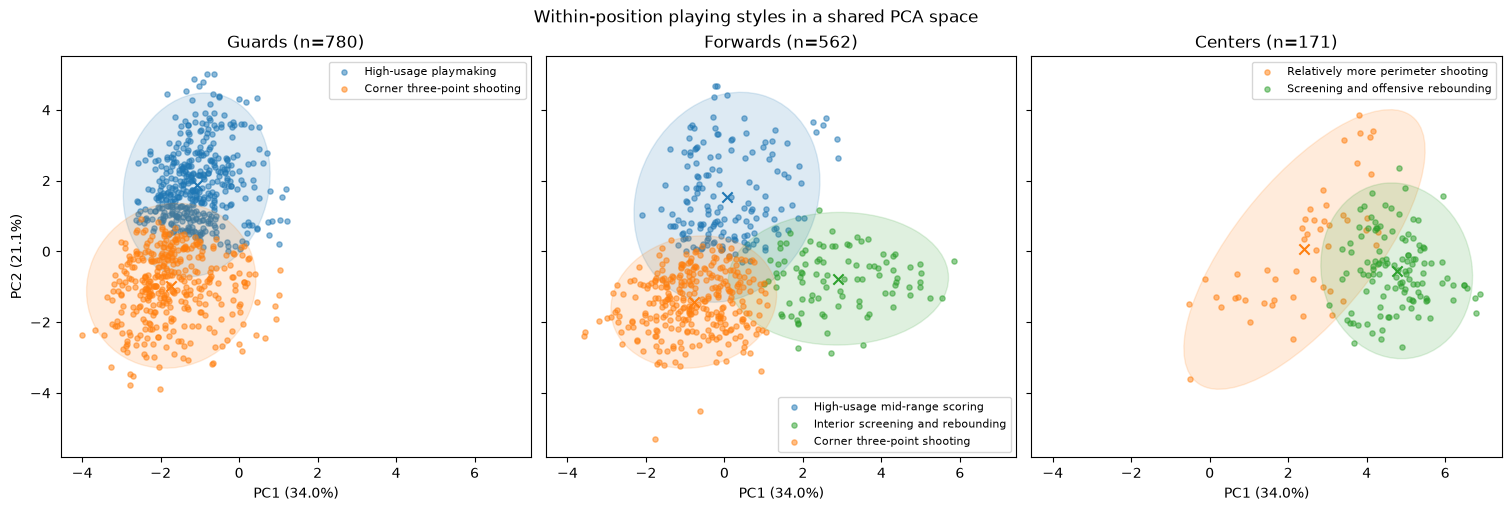

In [31]:
# Fit one shared PCA on all 1,979 player-seasons
pca_23 = PCA(n_components=2, svd_solver="full").fit(X)
pc1_share, pc2_share = pca_23.explained_variance_ratio_

position_titles = {"G": "Guards", "F": "Forwards", "C": "Centers"}
position_colors = {
    "G": ["tab:blue", "tab:orange"],
    "F": ["tab:blue", "tab:green", "tab:orange"],
    "C": ["tab:orange", "tab:green"],
}

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True, layout="constrained"
)

for ax, (pos, features, group_labels, role_names) in zip(axes, selected_groups):
    scores = pca_23.transform(features[feature_cols])

    for k, role in enumerate(role_names):
        points = scores[group_labels == k]
        color = position_colors[pos][k]
        center = points.mean(axis=0)

        # Estimate an ellipse enclosing about 95% of the plotted points
        covariance = np.cov(points, rowvar=False)
        eigvals, eigvecs = np.linalg.eigh(covariance)
        rotated = (points - center) @ eigvecs
        squared_distances = np.sum(rotated**2 / eigvals, axis=1)
        cutoff = np.quantile(squared_distances, 0.95)

        width, height = 2 * np.sqrt(cutoff * eigvals[::-1])
        angle = np.degrees(np.arctan2(eigvecs[1, 1], eigvecs[0, 1]))

        ellipse = Ellipse(
            center, width, height, angle=angle,
            facecolor=color, edgecolor=color, alpha=0.15,
        )
        ax.add_patch(ellipse)
        ax.scatter(points[:, 0], points[:, 1], s=14, alpha=0.5,
                   color=color, label=role)
        ax.scatter(*center, marker="x", s=55, color=color)

    ax.set_title(f"{position_titles[pos]} (n={len(features)})")
    ax.set_xlabel(f"PC1 ({pc1_share:.1%})")
    ax.legend(fontsize=8)

axes[0].set_ylabel(f"PC2 ({pc2_share:.1%})")
fig.suptitle("Within-position playing styles in a shared PCA space")
plt.show()

**Guards**, The high-usage playmaking group tends to sit higher on PC2 than the corner three-point shooting group. The two groups overlap in the middle of the plot, showing that some guard player-seasons have similar profiles in this projection.

**Forwards**, The three groups occupy different parts of the plot. Higher-usage mid-range scorers tend to sit higher on PC2, corner three-point shooters cluster toward the lower left, and interior screeners and rebounders tend to sit farther right on PC1. The groups still overlap where they meet.

**Centers**, The screening and offensive rebounding group tends to sit farther right on PC1. Centers who take relatively more perimeter shots are more spread out, and the two groups overlap. The two profiles describe tendencies within centers.

We retained K = 2 for guards because it had both better separation and greater stability under player-level resampling. For forwards, we retained K = 3 because it had a slightly higher silhouette score, similar stability, and distinguished higher-usage mid-range scorers from interior screeners and rebounders. For centers, we kept K = 2 as a simpler description, although K = 3 was more stable under resampling. Among hybrid positions, three clusters were worth exploring for F-G, F-C, and C-F. The smallest C-F subgroup contained 10 player-seasons from only three players, so we treat it as exploratory.

### 2.4 Checking Player Subtypes Using Additional Statistics

In [32]:
join_keys = ["PLAYER_ID", "SEASON"]
made_col = "FG3M_player_totals"
assisted_col = "PCT_AST_3PM_player_scoring"

shooting_stats = pd.read_csv(
    "data/player_season_joined.csv",
    usecols=join_keys + [made_col, assisted_col],
)

guard_roles = df.loc[X_g.index, join_keys].copy()
guard_roles["Cluster"] = guard_labels[2]

guard_shooting = guard_roles.merge(
    shooting_stats, on=join_keys, how="left", validate="one_to_one"
)

eligible = guard_shooting.loc[
    guard_shooting[made_col].ge(20) & guard_shooting[assisted_col].notna()
].copy()
eligible["Assisted threes (%)"] = eligible[assisted_col] * 100

guard_check = eligible.groupby("Cluster").agg(
    Records=("Assisted threes (%)", "size"),
    Median_assisted_threes_pct=("Assisted threes (%)", "median"),
)

guard_check.index = guard_check.index.map({
    0: "High-usage playmaking",
    1: "Corner three-point shooting",
})
guard_check.round(1)

,Records,Median_assisted_threes_pct
Cluster,,
High-usage playmaking,382,70.9
Corner three-point shooting,350,92.3


Among guard player-seasons with at least 20 made three-pointers, the corner three-point shooting group had a higher median share of assisted three-point makes than the high-usage playmaking group (92.3% vs. 70.9%). This measure was held out of clustering and provides additional support for the distinction between the two playing styles.

In [33]:
blocks_col = "BLK_player_totals"
minutes_col = "MIN_player_totals"

block_stats = pd.read_csv(
    "data/player_season_joined.csv",
    usecols=join_keys + [blocks_col],
)

forward_roles = df.loc[X_f.index, join_keys + [minutes_col]].copy()
forward_roles["Cluster"] = forward_labels[3]

forward_blocks = forward_roles.merge(
    block_stats, on=join_keys, how="left", validate="one_to_one"
)

forward_blocks = forward_blocks.loc[
    forward_blocks[minutes_col].gt(0) & forward_blocks[blocks_col].notna()
].copy()
forward_blocks["Blocks per 36"] = (
    forward_blocks[blocks_col] / forward_blocks[minutes_col] * 36
)

forward_check = forward_blocks.groupby("Cluster").agg(
    Records=("Blocks per 36", "size"),
    Median_blocks_per_36=("Blocks per 36", "median"),
)

forward_check.index = forward_check.index.map({
    0: "High-usage mid-range scoring",
    1: "Interior screening and rebounding",
    2: "Corner three-point shooting",
})
forward_check.round(2)

,Records,Median_blocks_per_36
Cluster,,
High-usage mid-range scoring,161,0.59
Interior screening and rebounding,95,1.03
Corner three-point shooting,306,0.59


The interior screening and rebounding group had a median of 1.03 blocks per 36 minutes, compared with 0.59 in each of the other two forward groups. Blocks were held out of clustering, so this result provides additional support for the group’s interior profile.

In [34]:
role_export = players_k3[
    ["PLAYER_ID", "PLAYER_NAME", "SEASON", "PLAYER_POSITION_defend_rim", "Cluster", "Role"]
].copy()

role_export = role_export.rename(columns={
    "PLAYER_POSITION_defend_rim": "LISTED_POSITION",
    "Cluster": "LEAGUE_CLUSTER",
    "Role": "LEAGUE_ROLE",
})

role_export["POSITION_SUBTYPE"] = pd.Series(
    pd.NA, index=role_export.index, dtype="string"
)

for pos, features, group_labels, role_names in selected_groups:
    role_export.loc[features.index, "POSITION_SUBTYPE"] = [
        f"{pos} | {role_names[k]}" for k in group_labels
    ]

assert len(role_export) == len(df)
assert not role_export.duplicated(["PLAYER_ID", "SEASON"]).any()
assert role_export["LEAGUE_ROLE"].notna().all()
assert role_export["POSITION_SUBTYPE"].nunique() == 7

role_export.to_csv("player_roles_kmeans.csv", index=False)

print("Player-season records:", len(role_export))
print("Records with a position subtype:", role_export["POSITION_SUBTYPE"].count())
role_export.head()

Player-season records: 1979
Records with a position subtype: 1513


,PLAYER_ID,PLAYER_NAME,SEASON,LISTED_POSITION,LEAGUE_CLUSTER,LEAGUE_ROLE,POSITION_SUBTYPE
0,2544,LeBron James,2021-22,F,2,On-ball playmaking & scoring,F | High-usage mid-range scoring
1,2544,LeBron James,2022-23,F,2,On-ball playmaking & scoring,F | High-usage mid-range scoring
2,2544,LeBron James,2023-24,F,2,On-ball playmaking & scoring,F | High-usage mid-range scoring
3,2544,LeBron James,2024-25,F,2,On-ball playmaking & scoring,F | High-usage mid-range scoring
4,2544,LeBron James,2025-26,F,2,On-ball playmaking & scoring,F | High-usage mid-range scoring
